# Лабораторная работа № 1 «Знакомство с нейронными сетями»

**Выполнил:** Федотов Георгий Николаевич  
**Группа:** ИТ-23д  
**Вариант:** № 37

**Цель работы:** познакомиться с устройством нейронной сети, научиться программировать прохождение сигнала через её слои и посмотреть, как значения весов меняют результат.

## Порядок выполнения работы

1. Нарисовать схему сети для своего варианта.
2. Записать формулы вычислений на каждом слое.
3. Реализовать сеть на Python и подать на неё два тестовых сигнала.
4. Сравнить выходы при трёх диапазонах знаков весов и трёх масштабах.
5. Сформулировать выводы и ответить на контрольные вопросы.


### 1. Создание схемы нейронной сети согласно варианту


| Элемент сети | По варианту № 37 | Что это значит |
|---|---|---|
| Входы | 2 | В каждый момент сеть получает два числа: $x_1$ и $x_2$. |
| Скрытый слой | 12 нейронов | Каждый из 12 нейронов обрабатывает оба входных числа. |
| Выходы | 2 | Сеть возвращает два числа: $Y_1$ и $Y_2$. |
| Активация скрытого слоя | Leaky ReLU | Положительные значения остаются прежними, отрицательные сильно уменьшаются. |
| Активация выходного слоя | Softmax | Два выхода преобразуются в доли, сумма которых равна 1. |

Краткая запись схемы: **$x_1,x_2 \longrightarrow P_1,\dots,P_{12}\longrightarrow Y_1,Y_2$**. Это сеть прямого распространения: сигнал движется слева направо. Она называется полносвязной, потому что каждый нейрон одного слоя связан с каждым нейроном следующего.

От входов к скрытому слою идут $2\cdot12=24$ связи. От скрытого слоя к выходам идут $12\cdot2=24$ связи. Всего в этой модели **48 настраиваемых весов**. Смещения $b$ принимаем равными нулю, как в вычислительном примере исходного задания. Сеть в этой работе не обучается: веса нужны для исследования прямого прохода.

**Схема нейронной сети:** на рисунке ниже каждая линия соответствует одному весу. Слева два входа, посередине 12 скрытых нейронов, справа два выхода.


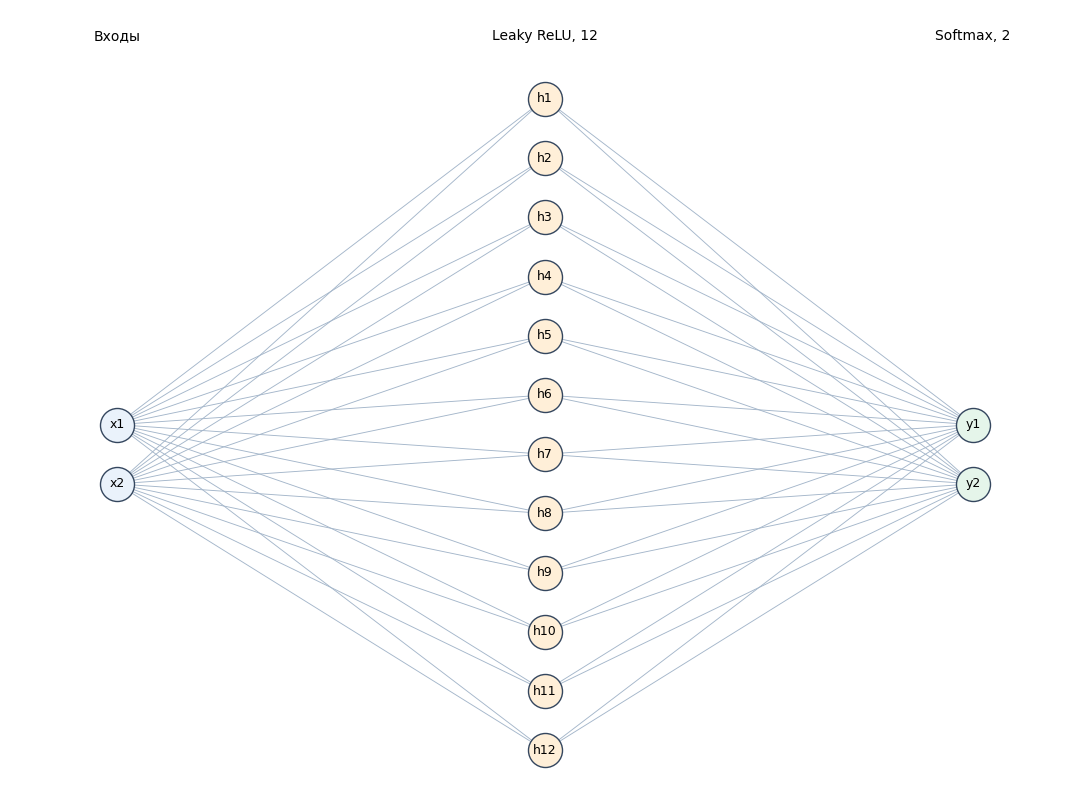

In [15]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 8))
pos = {**{f'x{i+1}':(0, 5.5-i*1.0) for i in range(2)},
       **{f'h{j+1}':(1, 11-j) for j in range(12)},
       **{f'y{q+1}':(2, 5.5-q*1.0) for q in range(2)}}
for i in range(2):
    for j in range(12):
        a, b = pos[f'x{i+1}'], pos[f'h{j+1}']
        ax.plot([a[0],b[0]], [a[1],b[1]], color='#a4b6ca', lw=.65, zorder=1)
for j in range(12):
    for q in range(2):
        a, b = pos[f'h{j+1}'], pos[f'y{q+1}']
        ax.plot([a[0],b[0]], [a[1],b[1]], color='#a4b6ca', lw=.65, zorder=1)
for label, (xx,yy) in pos.items():
    color = '#eaf2fb' if label[0]=='x' else ('#ffefd8' if label[0]=='h' else '#e5f5ea')
    ax.scatter(xx,yy,s=600,c=color,edgecolors='#34465e',zorder=2)
    ax.text(xx,yy,label,ha='center',va='center',fontsize=9,zorder=3)
ax.text(0,12,'Входы',ha='center'); ax.text(1,12,'Leaky ReLU, 12',ha='center'); ax.text(2,12,'Softmax, 2',ha='center')
ax.set(xlim=(-.25,2.25),ylim=(-.5,12.5)); ax.axis('off'); plt.tight_layout(); plt.show()

### 2. Создание математической модели нейронной сети согласно варианту

#### 2.1. Что означают обозначения

$x_i$ — значение входа, $w_{ji}^{(1)}$ — вес от входа $i$ к скрытому нейрону $j$, $S_j^{(1)}$ — сумма на входе этого нейрона, $P_j$ — значение после функции активации. На следующем слое $w_{qj}^{(2)}$ обозначает вес от скрытого нейрона $j$ к выходу $q$, а $z_q$ — его сумма до Softmax. Верхний индекс $(1)$ или $(2)$ указывает слой, а не степень.

#### 2.2. Первый (скрытый) слой

Каждый скрытый нейрон умножает **оба** входа на собственные веса, складывает произведения и применяет Leaky ReLU. Например, для первых двух нейронов:

$$S_1^{(1)}=x_1w_{11}^{(1)}+x_2w_{12}^{(1)},\qquad P_1=\operatorname{LeakyReLU}(S_1^{(1)}),$$
$$S_2^{(1)}=x_1w_{21}^{(1)}+x_2w_{22}^{(1)},\qquad P_2=\operatorname{LeakyReLU}(S_2^{(1)}).$$

Точно так же рассчитываются нейроны 3–11; последний нейрон:

$$S_{12}^{(1)}=x_1w_{12,1}^{(1)}+x_2w_{12,2}^{(1)},\qquad P_{12}=\operatorname{LeakyReLU}(S_{12}^{(1)}).$$

Таким образом, общая формула для всех двенадцати нейронов:

$$S_j^{(1)}=\sum_{i=1}^{2}x_iw_{ji}^{(1)},\quad P_j=\operatorname{LeakyReLU}(S_j^{(1)}),\quad j=1,\ldots,12.$$

Функция Leaky ReLU в работе задана так:

$$\operatorname{LeakyReLU}(s)=\begin{cases}s,&s\geq0,\\0{,}01s,&s<0.\end{cases}$$

Например, если сумма равна $3$, выход равен $3$. Если сумма равна $-2$, выход равен $-0{,}02$. Отрицательный сигнал не исчезает полностью, но становится в 100 раз меньше по модулю. Значение $0{,}01$ — выбранный для программы коэффициент отрицательной ветви.

#### 2.3. Второй (выходной) слой

Каждый из двух выходных нейронов получает значения **всех 12** скрытых нейронов:

$$z_1=P_1w_{11}^{(2)}+P_2w_{12}^{(2)}+\cdots+P_{12}w_{1,12}^{(2)},$$
$$z_2=P_1w_{21}^{(2)}+P_2w_{22}^{(2)}+\cdots+P_{12}w_{2,12}^{(2)}.$$

Компактно: $z_q=\sum_{j=1}^{12}P_jw_{qj}^{(2)}$, где $q=1,2$. Полученные суммы $z_1,z_2$ называют **логитами**. Затем Softmax рассчитывает выходы:

$$Y_1=\frac{e^{z_1}}{e^{z_1}+e^{z_2}},\qquad
Y_2=\frac{e^{z_2}}{e^{z_1}+e^{z_2}}.$$

В программе перед вычислением экспонент из обоих логитов вычитается их максимум. Это предотвращает переполнение при больших весах; результат формулы не меняется. Если $z_1=z_2$, то $Y_1=Y_2=0{,}5$. Если $z_1$ заметно больше $z_2$, то $Y_1$ ближе к 1, а $Y_2$ ближе к 0. **Всегда** $Y_1+Y_2=1$.

Softmax даёт числа, похожие на доли двух классов, но в опыте веса случайные и нет обучения. Поэтому здесь нельзя говорить о точности классификации или о достоверной вероятности реального класса.


## 3. Моделирование нейронной сети (практическое задание)

### 3.1. Реализация модели

В следующей ячейке определены три функции. `leaky_relu` применяет активацию к скрытому слою. `softmax` превращает два выходных логита в доли. `Neuron` последовательно выполняет оба слоя и возвращает массив результатов.


In [16]:
def leaky_relu(s, alpha=0.01):
    return np.where(s >= 0, s, alpha * s)

def softmax(z, axis=0):
    shifted = z - np.max(z, axis=axis, keepdims=True)
    exps = np.exp(shifted)
    return exps / np.sum(exps, axis=axis, keepdims=True)

def Neuron(WS, WV, Xx):
    WS, WV, Xx = map(np.asarray, (WS, WV, Xx))
    if WS.shape != (12, 2) or WV.shape != (2, 12) or Xx.ndim != 2 or Xx.shape[0] != 2:
        raise ValueError('Ожидаются WS: (12,2), WV: (2,12), Xx: (2,T)')
    hidden = leaky_relu(WS @ Xx)
    return softmax(WV @ hidden, axis=0)

assert np.allclose(leaky_relu(np.array([-2., 0., 3.])), [-.02, 0., 3.])
assert np.allclose(leaky_relu_derivative(np.array([-2., 0., 3.])), [.01, 1., 1.])
assert np.allclose(softmax(np.array([1000., 1000.])), [.5, .5])
print('Проверка активаций пройдена.')

Проверка активаций пройдена.


### 3.2. Подготовка и визуализация входных данных

Одновременно подадим два разных сигнала:

$$x_1(t)=0{,}05t+0{,}3,\qquad x_2(t)=\sin(t),\qquad -20\leq t\leq20.$$

Первый вход плавно растёт, второй колеблется. Так можно увидеть реакцию сети и на изменение общего уровня, и на колебания. Временная ось содержит 201 точку, поэтому $Xx$ имеет размер $(2,201)$. Эти формулы описывают **вход**, а не то, чему сеть обучается: целевые ответы для обучения в лабораторной не заданы. На двух графиках ниже показано, что именно поступает в сеть.


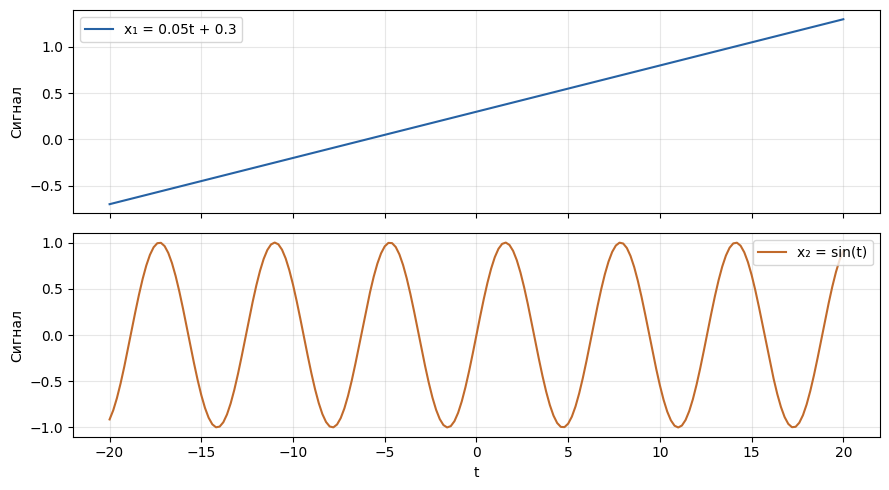

In [17]:
vx = np.linspace(-20, 20, 201)
Xx = np.vstack((0.05 * vx + 0.3, np.sin(vx)))
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(vx, Xx[0], label='x₁ = 0.05t + 0.3', color='#2662a4')
axes[1].plot(vx, Xx[1], label='x₂ = sin(t)', color='#c16a2b')
for ax in axes:
    ax.grid(alpha=.3); ax.legend(); ax.set_ylabel('Сигнал')
axes[1].set_xlabel('t'); fig.tight_layout(); plt.show()

### 3.3. Эксперименты с весами

Вес показывает, насколько сильно значение одного нейрона участвует в вычислении следующего. Функция `Wes` для каждого опыта создаёт две матрицы случайных весов нужного размера и запускает `Neuron`. Сравниваются три случая:

| Интервал | Значение опыта |
|---|---|
| $[a;0]$ | Все веса отрицательные. |
| $[a;b]$ | Веса могут быть как отрицательными, так и положительными. |
| $[0;b]$ | Все веса положительные. |

Эти три случая повторяются для обычного масштаба $[-1;1]$, уменьшенного в 10 раз $[-0{,}1;0{,}1]$ и увеличенного в 10 раз $[-10;10]$. Отрицательные и положительные интервалы в каждом масштабе имеют соответствующие границы. Везде используются **одни и те же входные сигналы**, а матрицы весов в каждом опыте новые. Генератор `default_rng(37)` обеспечивает воспроизводимый результат при повторном запуске всего ноутбука с начала.

На каждом рисунке три панели по диапазонам. В каждой панели две линии: $Y_1$ и $Y_2$. На вертикальной оси значения от 0 до 1, на горизонтальной — $t$. Если одна линия идёт вверх, другая идёт вниз, поскольку сумма двух выходов равна единице. Строки под рисунками показывают минимум, максимум и среднее значение $Y_1$; для $Y_2$ соответствующие значения дополняют их до единицы.


In [18]:
rng = np.random.default_rng(37)

def Wes(Xx, vx, a, b, rng):
    results = {}
    intervals = [(f'[{a}; 0]', a, 0), (f'[{a}; {b}]', a, b), (f'[0; {b}]', 0, b)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, (label, lo, hi) in zip(axes, intervals):
        WS = rng.uniform(lo, hi, (12, 2))
        WV = rng.uniform(lo, hi, (2, 12))
        y = Neuron(WS, WV, Xx)
        assert y.shape == (2, Xx.shape[1])
        assert np.all(np.isfinite(y)) and np.allclose(y.sum(axis=0), 1.0)
        results[label] = y
        ax.plot(vx, y[0], label='Y₁', lw=1.7)
        ax.plot(vx, y[1], label='Y₂', lw=1.7)
        ax.set(title=f'Веса {label}', xlabel='t', ylim=(-.03, 1.03))
        ax.grid(alpha=.25)
        ax.legend()
    axes[0].set_ylabel('Выход Softmax')
    fig.suptitle(f'Диапазоны весов при масштабе {b:g}')
    fig.tight_layout(); plt.show()
    for label, y in results.items():
        print(f'{label:>13} | Y₁ min={y[0].min():.3f}, max={y[0].max():.3f}, среднее={y[0].mean():.3f}')
    return results

#### 3.3.1. Базовый эксперимент

Берём случайные веса в интервалах $[-1;0]$, $[-1;1]$ и $[0;1]$. Выполняем одинаковые вычисления для двух входов $x_1(t)$ и $x_2(t)$ и сравниваем три графика. Рисунок показывает, какую форму приобретают два выхода при исходном масштабе весов.


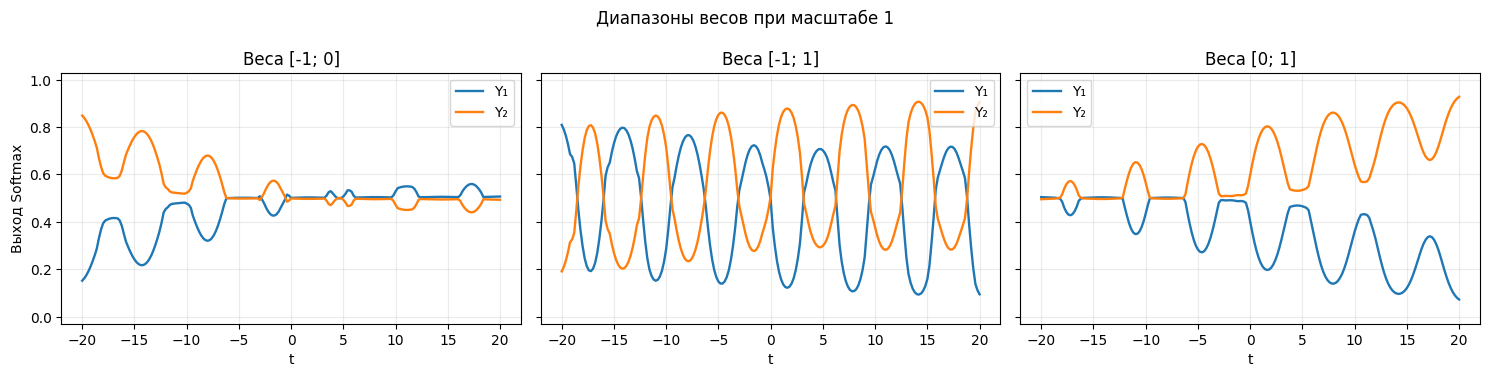

      [-1; 0] | Y₁ min=0.152, max=0.560, среднее=0.454
      [-1; 1] | Y₁ min=0.093, max=0.809, среднее=0.458
       [0; 1] | Y₁ min=0.072, max=0.504, среднее=0.361


In [19]:
base = Wes(Xx, vx, -1, 1, rng)

**Вывод по базовому эксперименту.** Графики отличаются и по высоте, и по характеру изменения: случайные веса по-разному объединяют растущий и колеблющийся входы. В смешанном интервале $[-1;1]$ значение $Y_1$ в этом запуске меняется примерно от **0,093 до 0,809**. При только отрицательных весах — от **0,152 до 0,560**, при только положительных — от **0,072 до 0,504**. Эти числа относятся к конкретному фиксированному набору случайных весов и показывают, что по одному знаку нельзя заранее определить, какой выход будет выше. Softmax удерживает значения в пределах от 0 до 1, а $Y_2=1-Y_1$.


#### 3.3.2. Эксперимент с уменьшением весов в 10 раз

Теперь диапазоны равны $[-0{,}1;0]$, $[-0{,}1;0{,}1]$ и $[0;0{,}1]$. Оба слоя получают меньшие по модулю веса. При вычислении скрытого слоя уменьшается взвешенная сумма, а при вычислении выходного слоя уменьшается вклад скрытых нейронов. Поэтому два логита обычно становятся ближе друг к другу.


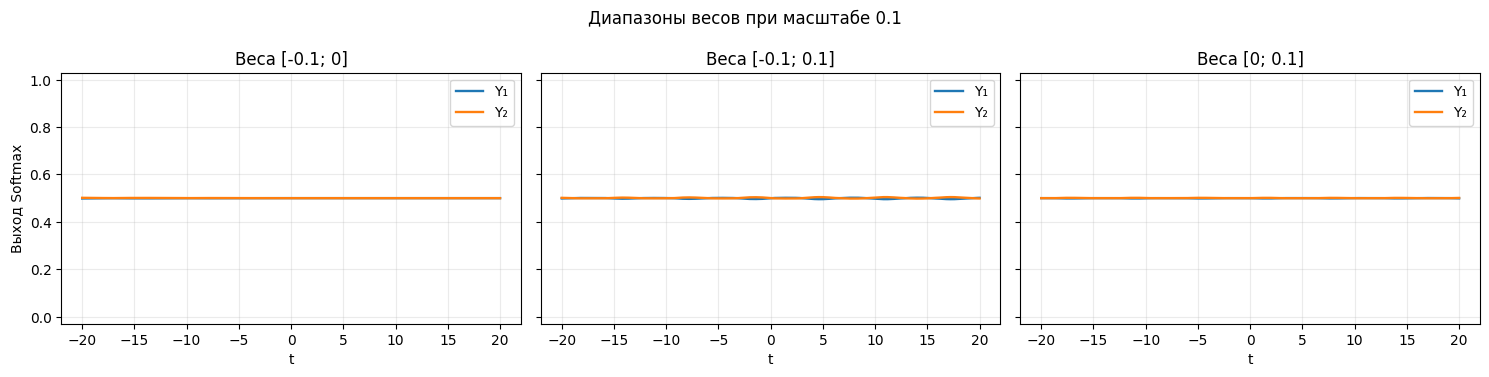

    [-0.1; 0] | Y₁ min=0.499, max=0.500, среднее=0.500
  [-0.1; 0.1] | Y₁ min=0.496, max=0.502, среднее=0.499
     [0; 0.1] | Y₁ min=0.499, max=0.501, среднее=0.500


In [20]:
small = Wes(Xx, vx, -0.1, 0.1, rng)

**Вывод по малым весам.** На всех трёх графиках линии расположены около **0,5** и почти совпадают. Например, в смешанном интервале $Y_1$ меняется только приблизительно от **0,496 до 0,502**. Это не ошибка построения графика: при близких к нулю логитах Softmax даёт двум выходам примерно равные доли. Уменьшение весов в обоих слоях ослабило реакцию на изменение входных сигналов.


#### 3.3.3. Эксперимент с увеличением весов в 10 раз

Проверяем интервалы $[-10;0]$, $[-10;10]$ и $[0;10]$. При больших по модулю весах логиты двух выходов могут сильно различаться. Softmax тогда даёт одному выходу значение, близкое к 1, а другому — близкое к 0. В программе использован устойчивый расчёт Softmax, поэтому даже большие значения не вызывают переполнения экспоненты.


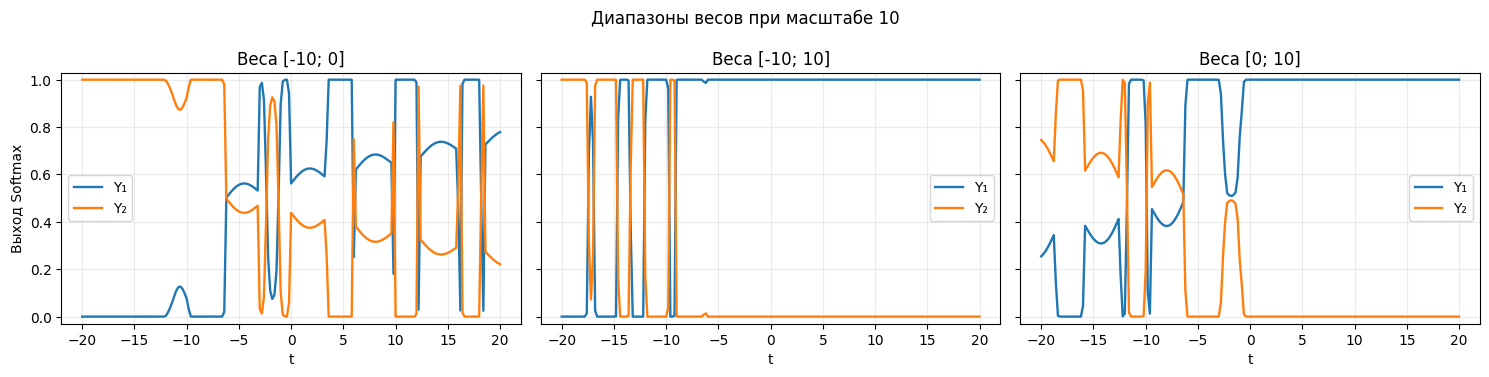

     [-10; 0] | Y₁ min=0.000, max=1.000, среднее=0.470
    [-10; 10] | Y₁ min=0.000, max=1.000, среднее=0.828
      [0; 10] | Y₁ min=0.000, max=1.000, среднее=0.758


In [21]:
large = Wes(Xx, vx, -10, 10, rng)

**Вывод по большим весам.** Во всех трёх случаях на данном запуске $Y_1$ достигает значений, которые при округлении до трёх знаков выглядят как **0,000** и **1,000**. Это означает сильное насыщение Softmax, а не строго нулевые или единичные значения. По сравнению с малым масштабом переходы стали резче. Где именно проходит переход и какой выход преобладает, зависит от конкретных сгенерированных матриц весов; крупные веса сами по себе не говорят о правильности ответа сети.


### 4. Общий вывод

В лабораторной работе построена двухслойная сеть варианта №37: два входа, двенадцать скрытых нейронов с Leaky ReLU и два выхода с Softmax. Программа принимает линейный и синусоидальный сигналы, вычисляет их прохождение через слои и строит графики результатов. При уменьшении весов выходы оказались близки к $0{,}5$, а при увеличении появились резкие переходы к значениям около 0 и 1. Знак и конкретные случайные значения весов определяют форму графиков; при этом оба выхода Softmax в любой точке дают в сумме 1. Обучение и проверка точности распознавания в задании не выполнялись.


### 5. Контрольные вопросы

**1. Понятие нейрона. Его математическая модель.**  
Искусственный нейрон — это небольшой вычислительный блок. Он получает несколько чисел, умножает каждое на вес, складывает результаты и при необходимости прибавляет смещение: $s=\sum_i w_ix_i+b$. Затем функция активации преобразует сумму: $y=f(s)$. В нашей программе смещение равно нулю, а скрытые нейроны используют Leaky ReLU.

**2. Что такое нейронная сеть?**  
Это система связанных нейронов, объединённых в слои. Выходы одного слоя поступают на вход следующего. Сеть позволяет последовательно преобразовывать данные и, если предусмотрено обучение, подбирать веса по примерам. В нашей модели от двух входных значений через 12 скрытых нейронов получаются два выхода.

**3. Свойства сигмоидальной функции активации.**  
Логистическая сигмоида имеет вид $\sigma(s)=1/(1+e^{-s})$. Она плавная, её значения находятся строго между 0 и 1, а при $s=0$ результат равен 0,5. Производная выражается как $\sigma(s)(1-\sigma(s))$, поэтому её удобно использовать при градиентном обучении. При очень больших положительных и отрицательных аргументах производная становится маленькой, что может замедлять обучение. В **нашем варианте** скрытый слой использует другую функцию — Leaky ReLU; Softmax применяется к паре выходов одновременно.

**4. Области применения нейронных сетей.**  
Нейронные сети применяют для распознавания объектов на изображениях, перевода и анализа текста, а также для распознавания речи. Их возможности зависят от качества данных, постановки задачи и обучения; случайно заданные веса из этой лабораторной таких задач ещё не решают.

**5. Однослойные и многослойные сети.**  
В однослойной сети вход сразу преобразуется выходным слоем. Многослойная сеть имеет хотя бы один промежуточный, скрытый слой. Благодаря нелинейной активации скрытого слоя она может описывать зависимости, которые нельзя выразить одним линейным преобразованием. Наш вариант содержит скрытый и выходной слои.

**6. Чем линейная активация отличается от нелинейной?**  
Линейная активация лишь пропорционально меняет число, например $f(s)=ks$. Несколько линейных слоёв подряд всё равно сводятся к одному линейному преобразованию. Нелинейные функции, в том числе Leaky ReLU, позволяют сети реагировать по-разному на разные области входов. Softmax в конце преобразует два логита в связанные значения от 0 до 1, сумма которых равна 1.
